# 03 Graph model (R-GCN): C-T, H-C and H-T prediction

Trains the R-GCN with DistMult heads on every fold of all four tasks, in two settings:
- **R-GCN**: every training link is a message edge and a scored link
- **R-GCN + fixes**: each epoch 30% of training links are taken out of the graph and only those are scored; in the new-compound and new-target
  tasks 15% of training compounds or targets also lose all their links; dropout on the fingerprint input and extra weight decay.
  These stop the model from memorising links it can see in the graph.

The graph: herbs, compounds and targets with four relations (herb to compound, compound to herb, compound to target, target to compound).
For C-T tasks only training C-T links are in the graph; for the H-C task only training H-C links are.
Compounds start from ECFP4 bits, targets from ESM-2, herbs from a learned vector plus their plant family.
Each model stops early on validation MRR. Herb-target scores come from compound-target scores (aggregation picked on validation).

Reads: `prep/` &nbsp; Writes: `results/metrics_rgcn.csv`, `results/curves_rgcn.csv`

## Setup

In [1]:
import hti
import time
import pandas as pd
import matplotlib.pyplot as plt
from hti.data import Prep, RESULTS, TASKS, TASK_NAMES, kind_of
from hti.metrics import evaluate
from hti.train import train_graph_model

RESULTS.mkdir(exist_ok=True)
prep = Prep()
print(prep.device, prep.n_herbs, 'herbs', prep.n_compounds, 'compounds', prep.n_targets, 'targets', prep.k, 'folds')

cuda 62 herbs 2319 compounds 1341 targets 5 folds


## One run, step by step
A single model on fold 0 of the hidden-link C-T task, printing training loss, validation loss and validation MRR as it trains.
The full loop below does the same for every task, fold and setting, without printing every epoch.

In [2]:
fold = prep.fold('ct_edge', 0)
scores, info, curve = train_graph_model(prep, fold, 'ct_edge', config='fixes', verbose=True)
print(info)
pd.DataFrame(evaluate(scores, fold, prep, 'ct')).T

  epoch   2  train loss 0.4941  val loss 0.3911  val MRR 0.0237
  epoch   4  train loss 0.3896  val loss 0.3330  val MRR 0.0765
  epoch   6  train loss 0.3386  val loss 0.2994  val MRR 0.1219
  epoch   8  train loss 0.3124  val loss 0.2669  val MRR 0.1054
  epoch  10  train loss 0.2902  val loss 0.2503  val MRR 0.1326
  epoch  12  train loss 0.2939  val loss 0.2463  val MRR 0.1428
  epoch  14  train loss 0.2649  val loss 0.2395  val MRR 0.1432
  epoch  16  train loss 0.2450  val loss 0.2349  val MRR 0.1243
  epoch  18  train loss 0.2580  val loss 0.2349  val MRR 0.1776
  epoch  20  train loss 0.2529  val loss 0.2286  val MRR 0.1182
  epoch  22  train loss 0.2141  val loss 0.2232  val MRR 0.1598
  epoch  24  train loss 0.2345  val loss 0.2181  val MRR 0.1647
  epoch  26  train loss 0.2190  val loss 0.2138  val MRR 0.1662
  epoch  28  train loss 0.2267  val loss 0.2113  val MRR 0.1755
  epoch  30  train loss 0.2113  val loss 0.2058  val MRR 0.1394
  epoch  32  train loss 0.2203  val loss

,PR-AUC,Hits@10,Hits@50,MRR,loss,n_pos,n_neg,HT PR-AUC,HT Hits@10,HT Hits@50,HT MRR,HT n_pos,HT aggregation,HT popularity weight,HT PR-AUC (model only),HT Hits@10 (model only),HT Hits@50 (model only),HT MRR (model only),HT aggregation (model only)
train,0.627589,0.590203,0.853047,0.391146,0.054738,9207,92070,0.738272,0.480857,0.687886,0.353344,20060,max,0.75,0.655437,0.305035,0.542323,0.186439,mean
val,0.516542,0.464941,0.703529,0.306961,0.193567,2125,21250,0.094059,0.166982,0.342479,0.096751,2114,max,0.75,0.084966,0.108325,0.258278,0.057656,mean
test,0.208711,0.473183,0.697601,0.309423,0.166409,2834,141700,0.120433,0.177001,0.343856,0.087693,2661,max,0.75,0.100926,0.10109,0.259301,0.049708,mean


## All tasks, folds and settings
About 40 models; on an RTX 4060 this takes roughly 20 to 40 minutes.

In [3]:
MODELS = {'R-GCN': 'plain', 'R-GCN + fixes': 'fixes'}
records, curves = [], []
start = time.time()
for task in TASKS:
    for name, config in MODELS.items():
        for k in range(prep.k):
            fold = prep.fold(task, k)
            scores, info, curve = train_graph_model(prep, fold, task, config=config, seed=k)
            result = evaluate(scores, fold, prep, kind_of(task))
            for part, metrics in result.items():
                records.append({'task': task, 'model': name, 'fold': k, 'set': part, **info, **metrics})
            curves += [{'task': task, 'model': name, 'fold': k, **c} for c in curve]
            test = result['test']
            ht = f"  HT MRR {test['HT MRR']:.3f}" if 'HT MRR' in test else ''
            print(f"{task:12s} {name:14s} fold {k}  test MRR {test['MRR']:.3f}  Hits@10 {test['Hits@10']:.3f}{ht}"
                  f"  best epoch {info['best epoch']:3d}  {time.time() - start:5.0f}s")

metrics = pd.DataFrame(records)
metrics.to_csv(RESULTS / 'metrics_rgcn.csv', index=False)
pd.DataFrame(curves).to_csv(RESULTS / 'curves_rgcn.csv', index=False)

ct_edge      R-GCN          fold 0  test MRR 0.287  Hits@10 0.448  HT MRR 0.081  best epoch  52     17s
ct_edge      R-GCN          fold 1  test MRR 0.278  Hits@10 0.447  HT MRR 0.081  best epoch  44     33s
ct_edge      R-GCN          fold 2  test MRR 0.295  Hits@10 0.443  HT MRR 0.065  best epoch  70     53s
ct_edge      R-GCN          fold 3  test MRR 0.307  Hits@10 0.450  HT MRR 0.081  best epoch  88     75s
ct_edge      R-GCN          fold 4  test MRR 0.301  Hits@10 0.440  HT MRR 0.065  best epoch  78     95s
ct_edge      R-GCN + fixes  fold 0  test MRR 0.277  Hits@10 0.426  HT MRR 0.080  best epoch 116    107s
ct_edge      R-GCN + fixes  fold 1  test MRR 0.266  Hits@10 0.400  HT MRR 0.084  best epoch  82    117s
ct_edge      R-GCN + fixes  fold 2  test MRR 0.286  Hits@10 0.433  HT MRR 0.073  best epoch 136    131s
ct_edge      R-GCN + fixes  fold 3  test MRR 0.274  Hits@10 0.424  HT MRR 0.086  best epoch  94    141s
ct_edge      R-GCN + fixes  fold 4  test MRR 0.238  Hits@10 0.37

## Mean and std over the 5 folds, for train, val and test

In [4]:
cols = ['PR-AUC', 'Hits@10', 'Hits@50', 'MRR', 'loss', 'HT PR-AUC', 'HT Hits@10', 'HT Hits@50', 'HT MRR']
g = metrics.groupby(['task', 'model', 'set'])[cols]
table = (g.mean().round(3).astype(str) + ' ± ' + g.std().round(3).astype(str)).replace('nan ± nan', '')
table.reindex(TASKS, level=0)

PR-AUC        Hits@10        Hits@50  \
task        model         set                                                  
ct_edge     R-GCN         test   0.135 ± 0.016  0.446 ± 0.004  0.666 ± 0.006   
                          train  0.626 ± 0.055   0.74 ± 0.038  0.939 ± 0.015   
                          val    0.421 ± 0.029  0.442 ± 0.017  0.673 ± 0.015   
            R-GCN + fixes test   0.219 ± 0.027  0.412 ± 0.024  0.669 ± 0.014   
                          train  0.619 ± 0.029  0.512 ± 0.026  0.788 ± 0.025   
                          val    0.535 ± 0.035  0.414 ± 0.018  0.665 ± 0.015   
ct_compound R-GCN         test   0.045 ± 0.009  0.073 ± 0.016  0.236 ± 0.021   
                          train   0.55 ± 0.074  0.549 ± 0.152  0.815 ± 0.114   
                          val    0.201 ± 0.056  0.088 ± 0.023   0.25 ± 0.055   
            R-GCN + fixes test   0.079 ± 0.015  0.142 ± 0.021  0.376 ± 0.041   
                          train  0.604 ± 0.021   0.463 ± 0.04  0.745 ± 0.034   
                          val    0.301 ± 0.037  0.164 ± 0.022  0.408 ± 0.037   
ct_target   R-GCN         test   0.062 ± 0.017  0.197 ± 0.029   0.487 ± 0.02   
                          train  0.582 ± 0.058  0.581 ± 0.109  0.852 ± 0.077   
                          val    0.271 ± 0.026  0.317 ± 0.035  0.615 ± 0.079   
            R-GCN + fixes test    0.14 ± 0.021  0.335 ± 0.035   0.63 ± 0.055   
                          train  0.662 ± 0.056   0.541 ± 0.12  0.817 ± 0.087   
                          val    0.388 ± 0.059  0.406 ± 0.052   0.703 ± 0.06   
hc_edge     R-GCN         test   0.105 ± 0.016   0.11 ± 0.012  0.261 ± 0.018   
                          train  0.977 ± 0.008  0.939 ± 0.024  0.993 ± 0.005   
                          val    0.321 ± 0.022  0.112 ± 0.018  0.266 ± 0.019   
            R-GCN + fixes test   0.136 ± 0.026  0.155 ± 0.011  0.371 ± 0.012   
                          train   0.432 ± 0.05  0.198 ± 0.013  0.438 ± 0.016   
                          val     0.41 ± 0.042  0.167 ± 0.018  0.364 ± 0.012   

                                           MRR           loss      HT PR-AUC  \
task        model         set                                                  
ct_edge     R-GCN         test   0.294 ± 0.012  0.329 ± 0.026  0.101 ± 0.005   
                          train   0.53 ± 0.048  0.025 ± 0.004  0.733 ± 0.014   
                          val    0.295 ± 0.019  0.327 ± 0.048  0.101 ± 0.012   
            R-GCN + fixes test   0.268 ± 0.019  0.166 ± 0.011  0.105 ± 0.008   
                          train  0.331 ± 0.021  0.079 ± 0.013  0.727 ± 0.006   
                          val    0.271 ± 0.021  0.166 ± 0.014   0.103 ± 0.01   
ct_compound R-GCN         test   0.036 ± 0.008   0.524 ± 0.05  0.092 ± 0.026   
                          train  0.347 ± 0.143  0.064 ± 0.042  0.716 ± 0.031   
                          val     0.05 ± 0.016  0.537 ± 0.099  0.066 ± 0.034   
            R-GCN + fixes test    0.072 ± 0.01  0.416 ± 0.093  0.094 ± 0.026   
                          train  0.287 ± 0.043  0.095 ± 0.021  0.713 ± 0.017   
                          val     0.082 ± 0.01  0.467 ± 0.118  0.065 ± 0.031   
ct_target   R-GCN         test   0.093 ± 0.019  0.652 ± 0.047                  
                          train  0.366 ± 0.104  0.075 ± 0.037                  
                          val    0.163 ± 0.034  0.566 ± 0.065                  
            R-GCN + fixes test   0.157 ± 0.017  0.522 ± 0.101                  
                          train  0.339 ± 0.102  0.098 ± 0.053                  
                          val    0.235 ± 0.063  0.495 ± 0.051                  
hc_edge     R-GCN         test   0.053 ± 0.006  0.746 ± 0.067                  
                          train   0.815 ± 0.04  0.004 ± 0.003                  
                          val    0.058 ± 0.008  0.739 ± 0.042                  
            R-GCN + fixes test   0.079 ± 0.006  0.289 ± 0.012                  
                          train  0.092 

## Training and validation curves (fold 0)

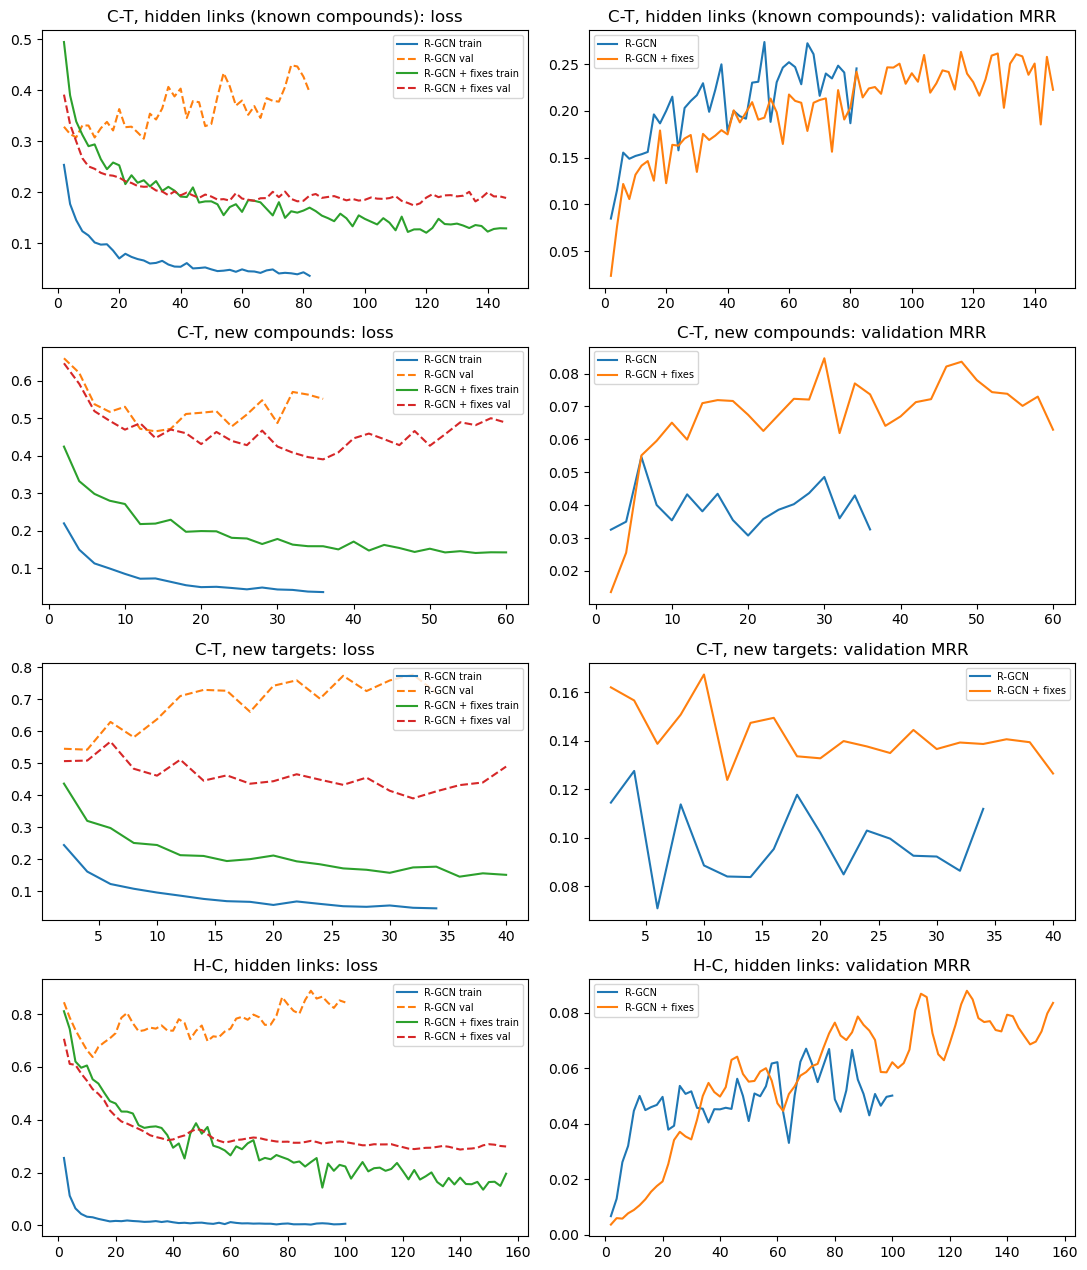

In [5]:
curves = pd.DataFrame(curves)
fig, axes = plt.subplots(len(TASKS), 2, figsize=(11, 3.2 * len(TASKS)))
for row, task in zip(axes, TASKS):
    for name in MODELS:
        c = curves[(curves.task == task) & (curves.model == name) & (curves.fold == 0)]
        row[0].plot(c['epoch'], c['train loss'], label=f'{name} train')
        row[0].plot(c['epoch'], c['val loss'], '--', label=f'{name} val')
        row[1].plot(c['epoch'], c['val MRR'], label=name)
    row[0].set_title(f'{TASK_NAMES[task]}: loss')
    row[1].set_title(f'{TASK_NAMES[task]}: validation MRR')
    row[0].legend(fontsize=7)
    row[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(RESULTS / 'curves_rgcn.png', dpi=110)
plt.show()